# Lecture 1: XAI Foundations & Interpretable Models

This lecture introduces why explanations matter, the main dimensions for classifying XAI methods, and two intrinsically interpretable model families: linear/logistic models and small decision trees. The goal is not merely to produce a score: it is to learn what the fitted model uses, when its explanation is trustworthy, and when it can mislead.

> **Dataset label convention:** in `load_breast_cancer`, `target=1` means **benign** and `target=0` means **malignant**. Always check label encodings before interpreting coefficient signs or predicted classes.

## Why explainability matters

- **Debugging:** explanations can expose shortcut learning, data leakage, or reliance on spurious proxies.
- **Trust and fairness:** domain experts and affected people may need to understand the factors behind a recommendation; auditors need evidence about performance and process.
- **Governance:** automated decisions may raise transparency, documentation, contestability, and human-oversight obligations. GDPR and the EU AI Act have distinct scopes and requirements; model explanations alone do not establish compliance.
- **Audience matters:** developers may want a feature-level debugging signal; clinicians may need a clinically meaningful rationale; affected individuals may need a concise account of a decision; auditors need reproducible evidence and limitations.

### Right answer, wrong reason

An image classifier may identify a **husky** because snow is present rather than because of the animal (Ribeiro et al., 2016). A healthcare model may appear accurate while exploiting hospital-specific artifacts or other proxies; Caruana et al. (2015) describe a pneumonia-risk example where a counterintuitive asthma association could be learned from treatment patterns. A prediction can therefore be correct while the reasoning is unsafe or non-generalizing.

### Interpretability–accuracy tradeoff

A useful rough spectrum is **linear/logistic models → small trees → ensembles → deep neural networks** (from generally easier to inspect to harder). It is not a universal ranking: on tabular data, a simple model can be competitive, and complexity does not guarantee better generalization. **Fit an interpretable baseline first**, then justify added complexity with measured benefit and appropriate explanations.

### XAI taxonomy: three questions

1. **When?** Intrinsic (the model is understandable by design) vs post-hoc (an explanation is added after fitting).
2. **How much?** Global (overall behavior) vs local (one prediction).
3. **What access?** Model-specific (uses internal structure) vs model-agnostic (works through input/output queries).

Examples: linear weights and tree rules (intrinsic/model-specific); SHAP, LIME, partial dependence (PDP), permutation feature importance (PFI), and counterfactuals (often post-hoc/model-agnostic); Grad-CAM for image-network internals; TreeSHAP and KernelSHAP are structure-aware and model-agnostic SHAP variants respectively. An explanation method answers a particular question, not every question.


## Learning objectives and workflow

We will compute standardized logistic odds ratios, examine correlated-feature instability, measure tree accuracy across depths, read one compact tree and a test case's path, then bootstrap trees and logistic regression to compare stability. A single stratified split is created below and reused throughout; all sources are built into scikit-learn, with no downloads.

### Setup — purpose and theory
Load the built-in dataset, define its label meaning, and create one stratified train/test split (75%/25%) with a fixed seed. Stratification preserves class proportions; reusing this split makes the comparisons consistent. The setup cell is the notebook’s sole imports/setup cell.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

RANDOM_STATE = 0
np.random.seed(RANDOM_STATE)
data = load_breast_cancer(as_frame=True)
X, y = data.data, data.target  # target 1 = benign; target 0 = malignant
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)
print(f"Dataset: {X.shape[0]} rows × {X.shape[1]} features")
print(f"Train/test sizes: {len(X_train)}/{len(X_test)}; benign prevalence: {y.mean():.3f}")
display(X.head())

Dataset: 569 rows × 30 features
Train/test sizes: 426/143; benign prevalence: 0.627


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


**How to read this output / takeaway.** The preview confirms 30 numeric measurements and the train/test counts; the prevalence gives a class-balance reference for interpreting accuracy. A stratified holdout is still only one estimate of generalization, and it does not replace external validation.

## Part 1 — Logistic regression and odds ratios

For a linear regression model, $\hat y=b_0+\sum_j b_jx_j$; coefficient $b_j$ is the model’s change in prediction per unit increase in $x_j$, **holding the other inputs fixed**. Logistic regression makes the **log-odds** linear: $\log\{p/(1-p)\}=b_0+\sum_jb_jx_j$. Thus $\exp(b_j)$ is the multiplicative change in modeled odds for a one-unit increase in that feature, conditional on the others. Standardizing makes a one-unit step equal to one training-set standard deviation.

**Cautions:** coefficients describe this fitted model, not causal effects in the world. Raw coefficient magnitudes depend on units; correlated features can make coefficients unstable or flip signs; and the linear/additive log-odds assumption may be inadequate. Here, since class 1 is **benign**, odds ratios above one indicate higher modeled odds of benign rather than malignant, conditional on the remaining features.

## 1. Accuracy

(Overall Accuracy) Proportion of all correct predictions (both positive and negative) out of the total number of cases.

$$\text{Accuracy} = \frac{TP + TN}{TP + TN + FP + FN}$$

### Example (Churn):

Out of 1,000 customers, 50 leave. A simple model that predicts every customer as "staying" achieves an Accuracy of 950/1,000=95%, but fails to identify a single actual customer who leaves.

### Medicine (Cancer Detection):

In a screening examination, 99 out of 100 people do not have cancer. If the test consistently classifies everyone as "healthy," it achieves an Accuracy of 99%. Nevertheless, the test is medically useless because it fails to detect the one patient who actually has cancer.

# 2. Precision

(Relevance / Accuracy of Positive Predictions) Proportion of actual positive cases among all cases predicted as positive. A high value helps prevent false alarms (False Positives).

$$\text{Precision} = \frac{TP}{TP + FP}$$

### Example (Churn):

The model classifies 100 customers as "at risk of churning" (TP+FP). Of these, 80 actually leave (TP). The Precision is 80/100=80%. The remaining 20% incorrectly receive a discount offer intended to retain them.

### Medicine (Cancer Detection):

The model raises an alarm for 50 patients (TP+FP). After a biopsy, it turns out that 40 actually have a tumor (TP). The Precision is 40/50=80%. The remaining 10 people experience unnecessary anxiety and have to undergo an invasive tissue removal procedure (False Positive).

# 3. Recall

(Sensitivity / True Positive Rate) Proportion of correctly identified positive cases among all actual positive cases. A high value is essential when positive cases must not be overlooked (avoiding False Negatives).
$$\text{Recall} = \frac{TP}{TP + FN}$$

### Example (Churn):

There are a total of 50 customers who intend to leave (TP+FN). The model identifies 45 of them (TP). The Recall is 45/50=90%. Five customers are lost without being detected.

### Medicine (Cancer Detection):

The patient group contains 20 people with a tumor (TP+FN). The model identifies 19 of them (TP). The Recall is 19/20=95%. The one undetected patient (FN) is sent home with an undiagnosed, potentially incurable disease.

Importance in Medical Diagnostics

In medicine (particularly in cancer detection), the consequences of prediction errors are asymmetric:

Maximizing Recall Is Vital:

A False Negative result (FN) means that a cancerous tumor remains undetected. Treatment is delayed, which can drastically reduce the chances of survival or even lead to death. Therefore, medical diagnostics primarily aim to achieve a very high Recall.

Balancing Recall with Precision:

A False Positive result (FP) causes psychological stress for the patient and additional costs and risks associated with invasive follow-up examinations (e.g., biopsies). Nevertheless, a certain number of False Positives is accepted as long as no actual tumors are overlooked.

# 4. F1-Score (Harmonic Mean)

The F1-Score combines Precision and Recall into a single metric. It uses the harmonic mean, which causes the overall score to decrease significantly whenever either of the two individual values is poor.
$$\text{F1-Score} = 2 \cdot \frac{\text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}} = \frac{2 \cdot TP}{2 \cdot TP + FP + FN}$$

### Example (Churn):

If a model has a Precision of 80% ($0.80$) and a Recall of 90% ($0.90$):

$$\text{F1-Score} = 2 \cdot \frac{0{,}80 \cdot 0{,}90}{0{,}80 + 0{,}90} = 2 \cdot \frac{0{,}72}{1{,}70} \approx 0{,}847 \quad (84{,}7\%)$$

### Medicine (Cancer Detection):

If a model simply classified all patients as sick, its Recall would be a perfect 100%. However, its Precision would be extremely low (e.g., 2%) due to the enormous number of false alarms (FP).

The F1-Score penalizes this extreme imbalance and would be only approximately 3.9%. It immediately demonstrates that the model is unsuitable for practical use.

### Task 1 — standardize, fit, and visualize odds ratios
**Purpose:** fit a logistic baseline using training-set scaling only, then compute `exp(coef)` per one standard deviation. **Theory:** an odds ratio (OR) of 1 is the no-change reference; ORs above/below 1 increase/decrease the odds of benign class 1. The plot uses a logarithmic x-axis so reciprocal effects are visually balanced.

Logistic regression test accuracy: 0.958
Top 5 features by |standardized coefficient| (OR for benign class):
                      coefficient  odds_ratio
radius error               -1.213      0.2972
worst texture              -1.107      0.3304
mean concave points        -1.106       0.331
worst radius              -0.9947      0.3698
worst concave points      -0.9245      0.3967


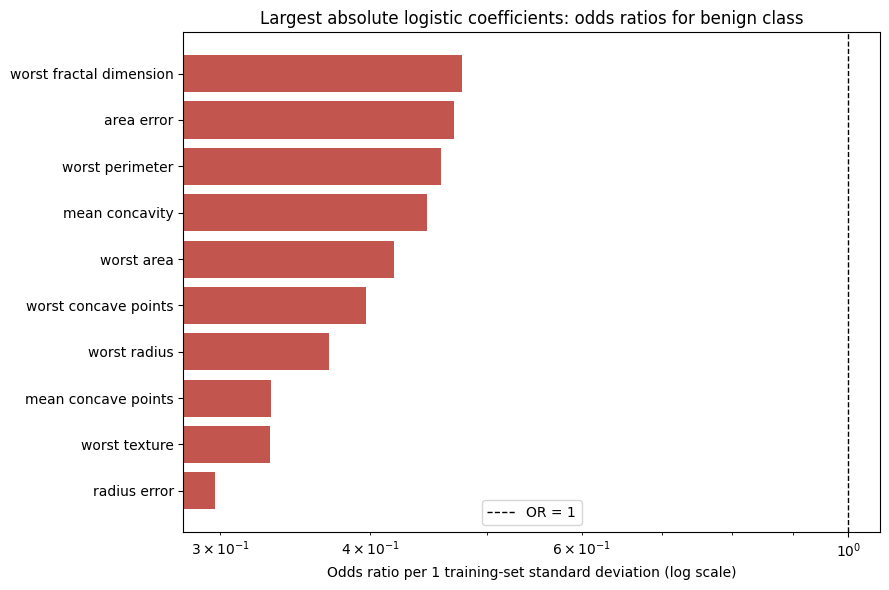

**Observed:** test accuracy is **0.958**. Across all features, the smallest fitted OR is **0.2972** for **radius error**, and the largest is **2.023** for **compactness error**. These are conditional associations in this fitted model, not causal effects. ORs shown are per one standard deviation and refer to *benign* class odds.

In [2]:
scaler = StandardScaler().fit(X_train)
Xtr = scaler.transform(X_train)
Xte = scaler.transform(X_test)
logreg = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE).fit(Xtr, y_train)
logreg_test_acc = accuracy_score(y_test, logreg.predict(Xte))
coef = pd.Series(logreg.coef_[0], index=X.columns, name="coefficient")
all_or = np.exp(coef)
top_abs_features = coef.abs().nlargest(10).index
or_top_abs = all_or.loc[top_abs_features].sort_values()
print(f"Logistic regression test accuracy: {logreg_test_acc:.3f}")
print("Top 5 features by |standardized coefficient| (OR for benign class):")
print(pd.DataFrame({"coefficient": coef.loc[top_abs_features].sort_values(key=np.abs, ascending=False).head(5),
                    "odds_ratio": all_or.loc[coef.abs().nlargest(5).index]}).to_string(float_format=lambda v: f"{v:.4g}"))
fig, ax = plt.subplots(figsize=(9, 6))
colors = ["#c2554d" if v < 1 else "#287a78" for v in or_top_abs]
ax.barh(or_top_abs.index, or_top_abs.values, color=colors)
ax.axvline(1, color="black", linestyle="--", linewidth=1, label="OR = 1")
ax.set_xscale("log")
ax.set_xlabel("Odds ratio per 1 training-set standard deviation (log scale)")
ax.set_title("Largest absolute logistic coefficients: odds ratios for benign class")
ax.legend(); fig.tight_layout(); plt.show()
smallest_or_feature, largest_or_feature = all_or.idxmin(), all_or.idxmax()
display(Markdown(f"**Observed:** test accuracy is **{logreg_test_acc:.3f}**. Across all features, the smallest fitted OR is **{all_or[smallest_or_feature]:.4g}** for **{smallest_or_feature}**, and the largest is **{all_or[largest_or_feature]:.4g}** for **{largest_or_feature}**. These are conditional associations in this fitted model, not causal effects. ORs shown are per one standard deviation and refer to *benign* class odds."))

**How to read the output.** ORs far from the dashed line at 1 correspond to stronger fitted associations on this standardized scale. Red marks OR < 1 and teal OR > 1 for benign odds. The accompanying result panel computes the extreme ORs from the fitted model, avoiding hard-coded claims. Correlated predictors can share or exchange signal, so do not treat rankings as definitive feature importance. **Takeaway:** scaling aids comparison, but neither ORs nor coefficients establish causation.

### Task 2 — correlated features and a reduced refit
**Purpose:** inspect the correlations among mean radius, perimeter, and area, then refit the model using mean radius alone from this trio (plus all unrelated features). **Theory:** correlated predictors contain overlapping information; conditional coefficients can become unstable when several near-duplicates compete. **Pitfall:** changing one feature set changes the model being described, so compare direction and magnitude as a diagnostic, not as evidence of a causal relationship.

In [ ]:
triad = ["mean radius", "mean perimeter", "mean area"]
print("Correlation matrix for the three size measurements:")
print(X_train[triad].corr().round(3).to_string())
reduced_features = [c for c in X.columns if c not in ["mean perimeter", "mean area"]]
reduced_scaler = StandardScaler().fit(X_train[reduced_features])
Xr_train = reduced_scaler.transform(X_train[reduced_features])
Xr_test = reduced_scaler.transform(X_test[reduced_features])
reduced_logreg = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE).fit(Xr_train, y_train)
radius_full_coef = float(coef["mean radius"])
radius_reduced_coef = float(reduced_logreg.coef_[0][reduced_features.index("mean radius")])
print(f"\nStandardized mean-radius coefficient: full model={radius_full_coef:.4f}; reduced model={radius_reduced_coef:.4f}")
reduced_accuracy = reduced_logreg.score(Xr_test, y_test)
print(f"Full vs reduced test accuracy: {logreg_test_acc:.3f} vs {reduced_accuracy:.3f}")
display(Markdown(f"**Observed:** mean radius coefficient changes from **{radius_full_coef:.4f}** (with all 30 features) to **{radius_reduced_coef:.4f}** after dropping mean perimeter and mean area. Their correlations with mean radius are **{X_train['mean radius'].corr(X_train['mean perimeter']):.3f}** and **{X_train['mean radius'].corr(X_train['mean area']):.3f}**. Test accuracy changes from **{logreg_test_acc:.3f}** to **{reduced_accuracy:.3f}**. This demonstrates predictor-set dependence, not causality."))

Correlation matrix for the three size measurements:
                mean radius  mean perimeter  mean area
mean radius           1.000           0.998      0.987
mean perimeter        0.998           1.000      0.986
mean area             0.987           0.986      1.000

Standardized mean-radius coefficient: full model=-0.5442; reduced model=-0.8170
Full vs reduced test accuracy: 0.958 vs 0.965


**Observed:** mean radius coefficient changes from **-0.5442** (with all 30 features) to **-0.8170** after dropping mean perimeter and mean area. Their correlations with mean radius are **0.998** and **0.987**. Test accuracy changes from **0.958** to **0.965**. This demonstrates predictor-set dependence, not causality.

**How to read the output / takeaway.** Near-unit absolute correlations indicate strong redundancy; compare the radius coefficient before and after removing perimeter and area. Changes in sign or size illustrate multicollinearity and conditional interpretation. Remaining features can still be correlated, and the reduced model is not necessarily better simply because it is simpler.

## Part 2 — Decision trees and the depth tradeoff

A decision tree makes predictions through sequential if–then tests. Shallow trees can capture some nonlinearities and interactions while remaining readable; increasing depth usually lets training accuracy rise, but can overfit and makes the rule set harder to inspect. Axis-aligned thresholds can be awkward for some relationships, and trees can be unstable: small data changes may select different splits. A deep tree is not automatically interpretable.

### Accuracy versus depth
**Purpose:** fit trees at depths 1–15 on the same training data and compare train and test accuracy. **Theory:** the gap between curves is a simple overfitting signal; the best test score is not automatically the best explanation. Select the smallest depth within one percentage point of the best observed test accuracy.

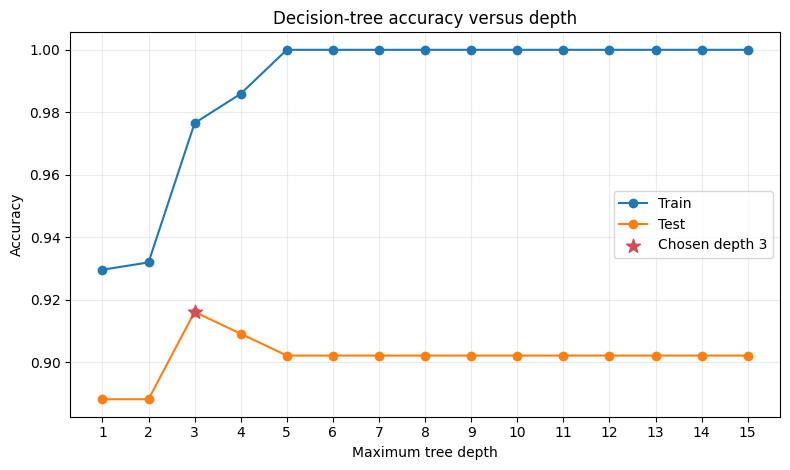

Best observed test accuracy: 0.916 at depth 3
Chosen smallest depth within 0.01: 3; train=0.977, test=0.916


**Observed:** the highest test accuracy is **0.916** at depth **3**. The selected smallest depth within 0.01 is **3**, with train accuracy **0.977** and test accuracy **0.916**. This favors a compact model near the best holdout score, not a claim that this split identifies a universally optimal depth.

In [ ]:
depths = list(range(1, 16))
train_acc, test_acc = [], []
for d in depths:
    model = DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE).fit(X_train, y_train)
    train_acc.append(model.score(X_train, y_train))
    test_acc.append(model.score(X_test, y_test))
best_test_depth = depths[int(np.argmax(test_acc))]
best_test_accuracy = max(test_acc)
eligible_depths = [d for d, score in zip(depths, test_acc) if score >= best_test_accuracy - 0.01]
best_depth = min(eligible_depths)
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.plot(depths, train_acc, marker="o", label="Train")
ax.plot(depths, test_acc, marker="o", label="Test")
ax.scatter([best_depth], [test_acc[best_depth-1]], s=110, marker="*", color="#d24d57", zorder=5, label=f"Chosen depth {best_depth}")
ax.set(xticks=depths, xlabel="Maximum tree depth", ylabel="Accuracy", title="Decision-tree accuracy versus depth")
ax.grid(alpha=.25); ax.legend(); fig.tight_layout(); plt.show()
print(f"Best observed test accuracy: {best_test_accuracy:.3f} at depth {best_test_depth}")
print(f"Chosen smallest depth within 0.01: {best_depth}; train={train_acc[best_depth-1]:.3f}, test={test_acc[best_depth-1]:.3f}")
display(Markdown(f"**Observed:** the highest test accuracy is **{best_test_accuracy:.3f}** at depth **{best_test_depth}**. The selected smallest depth within 0.01 is **{best_depth}**, with train accuracy **{train_acc[best_depth-1]:.3f}** and test accuracy **{test_acc[best_depth-1]:.3f}**. This favors a compact model near the best holdout score, not a claim that this split identifies a universally optimal depth."))

**How to read the plot.** Training accuracy is in-sample; test accuracy is measured on held-out data. The star marks the deliberately parsimonious choice, not necessarily the highest test point. With only one split, small score differences are noisy; cross-validation would provide a stronger selection estimate. **Takeaway:** depth is an explicit simplicity/performance control.

### Compare an interpretable tree, logistic baseline, and random forest
**Purpose:** fit the selected-depth tree and a 200-tree random forest, and compare both with the already-fitted logistic baseline. **Theory:** ensembles can improve predictive performance by aggregating many trees, at the cost of a less transparent overall decision process. All scores here use the same holdout.

In [ ]:
selected_tree = DecisionTreeClassifier(max_depth=best_depth, random_state=RANDOM_STATE).fit(X_train, y_train)
rf = RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1).fit(X_train, y_train)
model_scores = pd.Series({
    "Logistic regression": logreg_test_acc,
    f"Decision tree (depth {best_depth})": selected_tree.score(X_test, y_test),
    "Random forest (200 trees)": rf.score(X_test, y_test)
})
print("Test accuracy comparison:")
print(model_scores.to_string(float_format=lambda v: f"{v:.3f}"))
display(Markdown(f"**Observed:** on this holdout, logistic regression scores **{model_scores.iloc[0]:.3f}**, the selected shallow tree **{model_scores.iloc[1]:.3f}**, and the random forest **{model_scores.iloc[2]:.3f}**. Compare score and interpretability together; the benchmark does not establish that one model is preferable in every use case."))

Test accuracy comparison:
Logistic regression         0.958
Decision tree (depth 3)     0.916
Random forest (200 trees)   0.944


**Observed:** on this holdout, logistic regression scores **0.958**, the selected shallow tree **0.916**, and the random forest **0.944**. Compare score and interpretability together; the benchmark does not establish that one model is preferable in every use case.

**How to read the output / takeaway.** The score comparison measures only classification accuracy on this test split; it omits calibration, subgroup performance, uncertainty, clinical utility, and deployment costs. An ensemble may be selected only if its predictive benefit justifies its explanation and governance burden.

## Part 3 — Reading the rules of a tree

Tree rules provide a **global** description of the fitted tree, while tracing one sample through the nodes explains one **local** prediction. They describe the model's logic, not the underlying causal process. Tree splits are axis-aligned, may be unstable, and can be difficult to read when depth is large.

### Task 3 — inspect the selected shallow tree’s rules
**Purpose:** fit a depth-3 tree, print its if–then rules, and draw the tree. **Theory:** each internal node tests a single feature threshold; each leaf reports the class distribution and prediction. In this dataset, class names are explicitly mapped to 0=malignant and 1=benign.

|--- worst perimeter <= 106.100
|   |--- worst concave points <= 0.134
|   |   |--- area error <= 48.975
|   |   |   |--- class: 1
|   |   |--- area error >  48.975
|   |   |   |--- class: 0
|   |--- worst concave points >  0.134
|   |   |--- worst texture <= 26.000
|   |   |   |--- class: 1
|   |   |--- worst texture >  26.000
|   |   |   |--- class: 0
|--- worst perimeter >  106.100
|   |--- worst concave points <= 0.142
|   |   |--- worst radius <= 17.615
|   |   |   |--- class: 1
|   |   |--- worst radius >  17.615
|   |   |   |--- class: 0
|   |--- worst concave points >  0.142
|   |   |--- texture error <= 0.431
|   |   |   |--- class: 1
|   |   |--- texture error >  0.431
|   |   |   |--- class: 0



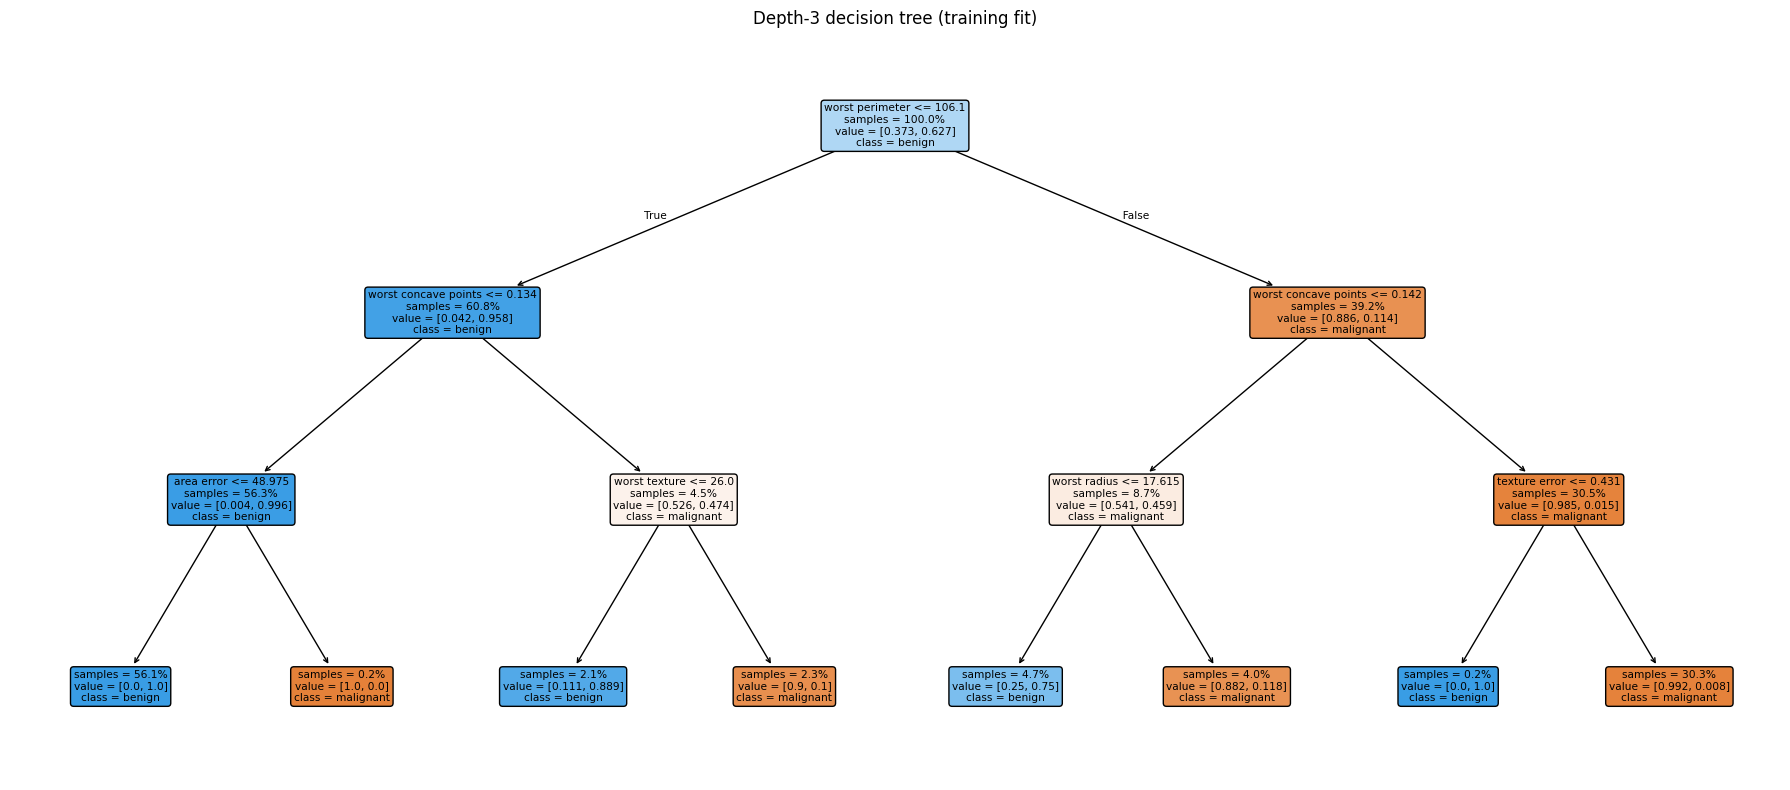

Depth-3 tree test accuracy: 0.916


**Observed:** this tree has maximum depth **3** and **8** leaves; its holdout accuracy is **0.916**. Read each threshold as a branch condition, and remember each leaf prediction is based on training samples reaching that leaf.

In [ ]:
small = DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE).fit(X_train, y_train)
print(export_text(small, feature_names=list(X.columns), decimals=3))
fig, ax = plt.subplots(figsize=(18, 8))
plot_tree(small, feature_names=list(X.columns), class_names=["malignant", "benign"], filled=True, rounded=True, proportion=True, ax=ax, impurity=False, precision=3)
ax.set_title("Depth-3 decision tree (training fit)")
fig.tight_layout(); plt.show()
print(f"Depth-3 tree test accuracy: {small.score(X_test, y_test):.3f}")
display(Markdown(f"**Observed:** this tree has maximum depth **{small.get_depth()}** and **{small.get_n_leaves()}** leaves; its holdout accuracy is **{small.score(X_test, y_test):.3f}**. Read each threshold as a branch condition, and remember each leaf prediction is based on training samples reaching that leaf."))

**How to read the output.** In the text rules, `<=` follows the left branch and `>` the right. In the visualization, node colors indicate predicted class and shading reflects class purity; sample proportions are from the training set. Leaf class predictions may be wrong on individual unseen observations. **Takeaway:** rule transparency is useful, but must be paired with performance and stability checks.

### Task 4 — trace a held-out case
**Purpose:** choose a deterministic test row, obtain the nodes visited by `decision_path`, and report the exact decisions as plain-language conditions. **Theory:** a path is a local explanation of how this particular tree arrived at its prediction. It is not an explanation of why the biological condition occurred.

In [ ]:
sample = X_test.iloc[[0]]
sample_index = sample.index[0]
node_indicator = small.decision_path(sample)
leaf_id = small.apply(sample)[0]
visited_nodes = node_indicator.indices[node_indicator.indptr[0]:node_indicator.indptr[1]]
path_rules = []
for node_id in visited_nodes:
    if node_id == leaf_id:
        continue
    feature_id = small.tree_.feature[node_id]
    threshold = small.tree_.threshold[node_id]
    feature_name = X.columns[feature_id]
    value = sample.iloc[0, feature_id]
    relation = "≤" if value <= threshold else ">"
    path_rules.append(f"{feature_name} = {value:.4g} {relation} {threshold:.4g}")
true_label = int(y_test.loc[sample_index])
pred_label = int(small.predict(sample)[0])
print(f"Test row index: {sample_index}")
print("Path:")
for step, rule in enumerate(path_rules, 1):
    print(f"  {step}. {rule}")
print(f"Reached leaf {leaf_id}; prediction={pred_label} ({'benign' if pred_label == 1 else 'malignant'}), true={true_label} ({'benign' if true_label == 1 else 'malignant'})")
display(Markdown(f"**Observed local explanation:** this test case follows {len(path_rules)} split condition(s) to leaf **{leaf_id}**. Its prediction is **{'benign' if pred_label == 1 else 'malignant'}** and the true label is **{'benign' if true_label == 1 else 'malignant'}**. The conditions above explain the tree's output for this case only."))

Test row index: 532
Path:
  1. worst perimeter = 101.6 ≤ 106.1
  2. worst concave points = 0.08704 ≤ 0.1339
  3. area error = 17.25 ≤ 48.98
Reached leaf 3; prediction=1 (benign), true=1 (benign)


**Observed local explanation:** this test case follows 3 split condition(s) to leaf **3**. Its prediction is **benign** and the true label is **benign**. The conditions above explain the tree's output for this case only.

**How to read the output / takeaway.** Follow the listed feature comparisons in order; the final predicted label can be compared with the true held-out label. This is a model-specific, local account. It does not identify causal factors or establish clinical validity.

## Part 4 — Instability and bootstrap stability

A model explanation is more useful when it is reasonably stable under small data perturbations. Here, bootstrap resampling draws training rows with replacement, refits the same depth-3 tree, and records its root feature and threshold. We also refit standardized logistic regression on the same bootstrap draws. Coefficient variability is summarized as the median bootstrap standard deviation across standardized coefficients; it is a diagnostic, not a universal stability score. Bootstrapped scalers are refit within each resample, and coefficients are expressed per that resample's standard deviation.

### Task 5 — bootstrap root splits and coefficient stability
**Purpose:** use 40 bootstrap replicates to tally root-feature choices, summarize thresholds for the most common root feature, and compare logistic coefficient variation. **Theory:** a stable accuracy can coexist with unstable explanations. Thresholds should only be compared among runs that choose the same root feature. **Pitfall:** 40 resamples provide a useful classroom illustration, not a precise inferential uncertainty interval.

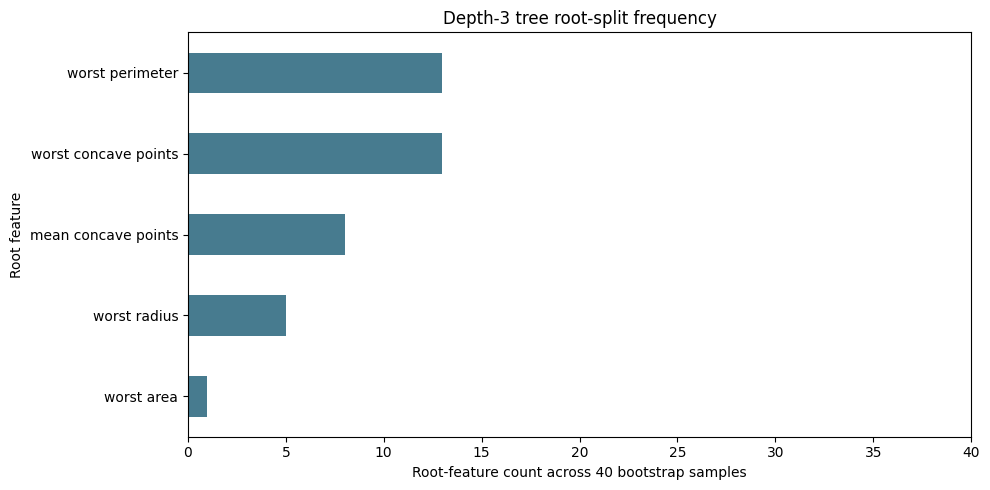

Root feature frequencies:
                      bootstrap count  frequency
root feature                                    
worst perimeter                    13      0.325
worst concave points               13      0.325
mean concave points                 8      0.200
worst radius                        5      0.125
worst area                          1      0.025

Most frequent root: worst perimeter (13/40 = 32.5%)
Thresholds when this feature was root: n=13, median=107.5, IQR=[106, 114.4]
Median across-feature bootstrap SD of standardized logistic coefficients: 0.2441
Largest coefficient SD: radius error (0.4679)
Bootstrap tree test-accuracy range: 0.881–0.958


**Observed stability:** the most frequent tree root is **worst perimeter**, selected in **13/40 (32.5%)** resamples. When selected, its threshold median is **107.5** (IQR **106–114.4**; n=13). Logistic coefficient bootstrap SD has median **0.2441** across features; the largest is **radius error** (**0.4679**). These different summaries are not directly commensurate: compare the tree's root choices and conditional threshold spread with coefficient variation, and interpret them alongside predictive performance.

In [ ]:
n_boot = 40
rng = np.random.RandomState(RANDOM_STATE)
root_records = []
boot_coefs = []
boot_tree_scores = []
for b in range(n_boot):
    idx = rng.choice(len(X_train), size=len(X_train), replace=True)
    Xb, yb = X_train.iloc[idx], y_train.iloc[idx]
    bt = DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE).fit(Xb, yb)
    root_id = bt.tree_.feature[0]
    root_records.append({"bootstrap": b + 1, "feature": X.columns[root_id], "threshold": bt.tree_.threshold[0],
                         "test_accuracy": bt.score(X_test, y_test)})
    bs = StandardScaler().fit(Xb)
    bl = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE).fit(bs.transform(Xb), yb)
    boot_coefs.append(bl.coef_[0])
root_df = pd.DataFrame(root_records)
root_counts = root_df["feature"].value_counts().sort_values(ascending=False)
root_freq = root_counts.rename_axis("root feature").to_frame("bootstrap count")
root_freq["frequency"] = root_freq["bootstrap count"] / n_boot
most_common_root = root_counts.index[0]
mode_thresholds = root_df.loc[root_df.feature == most_common_root, "threshold"]
coef_sd = pd.DataFrame(np.asarray(boot_coefs), columns=X.columns).std(axis=0, ddof=1)
median_coef_sd = float(coef_sd.median())
most_variable_coef = coef_sd.idxmax()
fig, ax = plt.subplots(figsize=(10, 5))
root_freq.sort_values("bootstrap count").plot.barh(y="bootstrap count", legend=False, ax=ax, color="#477b8f")
ax.set_xlabel(f"Root-feature count across {n_boot} bootstrap samples")
ax.set_ylabel("Root feature")
ax.set_title("Depth-3 tree root-split frequency")
ax.set_xlim(0, n_boot); fig.tight_layout(); plt.show()
print("Root feature frequencies:")
print(root_freq.to_string(float_format=lambda v: f"{v:.3f}"))
print(f"\nMost frequent root: {most_common_root} ({root_counts.iloc[0]}/{n_boot} = {root_counts.iloc[0]/n_boot:.1%})")
print(f"Thresholds when this feature was root: n={len(mode_thresholds)}, median={mode_thresholds.median():.4g}, IQR=[{mode_thresholds.quantile(.25):.4g}, {mode_thresholds.quantile(.75):.4g}]")
print(f"Median across-feature bootstrap SD of standardized logistic coefficients: {median_coef_sd:.4g}")
print(f"Largest coefficient SD: {most_variable_coef} ({coef_sd[most_variable_coef]:.4g})")
print(f"Bootstrap tree test-accuracy range: {root_df.test_accuracy.min():.3f}–{root_df.test_accuracy.max():.3f}")
display(Markdown(f"**Observed stability:** the most frequent tree root is **{most_common_root}**, selected in **{root_counts.iloc[0]}/{n_boot} ({root_counts.iloc[0]/n_boot:.1%})** resamples. When selected, its threshold median is **{mode_thresholds.median():.4g}** (IQR **{mode_thresholds.quantile(.25):.4g}–{mode_thresholds.quantile(.75):.4g}**; n={len(mode_thresholds)}). Logistic coefficient bootstrap SD has median **{median_coef_sd:.4g}** across features; the largest is **{most_variable_coef}** (**{coef_sd[most_variable_coef]:.4g}**). These different summaries are not directly commensurate: compare the tree's root choices and conditional threshold spread with coefficient variation, and interpret them alongside predictive performance."))

**How to read the output.** The bar chart shows how often each feature appears at the root; multiple root choices suggest structural instability. Threshold IQR is conditional on the modal root being chosen. Logistic coefficient SD is on the standardized scale per bootstrap fit; correlated predictors may have individually variable coefficients even when predictions remain similar. **Which is more stable?** Use the observed root frequency/threshold spread and coefficient dispersion rather than assuming a winner: they measure different aspects of explanation stability. More resamples, repeated external samples, or prediction-level comparisons would strengthen a substantive conclusion.

## Discussion and final summary

### Discussion prompts (with guidance)

1. **When accept a less accurate but interpretable model?** Potentially when the score difference is small or uncertain and transparent review, contestability, safety, or operational simplicity has value. For consequential decisions, validate utility and harms with domain experts rather than optimizing accuracy alone.
2. **Which models here are intrinsically interpretable?** Logistic regression has a global linear log-odds form (with conditional coefficient caveats); a shallow decision tree exposes global rules and each path gives a local rationale. A random forest aggregates many trees and is not transparently understood by reading one constituent tree.
3. **What about GDPR / EU AI Act in a clinical context?** Applicability depends on jurisdiction, role, system purpose, deployment, and current law. Relevant considerations may include information about automated decision-making and meaningful safeguards under GDPR where applicable, and AI Act transparency, risk-management, documentation, human oversight, and other obligations for regulated/high-risk systems. A clinical model may also engage medical-device and sectoral rules. Seek qualified legal/regulatory advice; an explanation plot does not itself satisfy a legal requirement.

### Takeaways

- Begin with a transparent baseline; evaluate both predictive performance and whether the model's reasoning is sensible for the task.
- Logistic coefficients and odds ratios are conditional descriptions of a fitted model; standardization helps compare scales, but correlated features and modeling assumptions complicate individual interpretations.
- Small trees produce readable rules, but depth trades readability against fit. Tree structure can be sensitive to resampling even when accuracy appears steady.
- Explanations have scope: global vs local, intrinsic vs post-hoc, model-specific vs model-agnostic. State what an explanation does and does not establish.
- Predictive association is not causality, fairness, robustness, clinical validity, or regulatory compliance.

### Pitfalls checklist

- [ ] Check target-label meanings before reading signs or class names.
- [ ] Fit preprocessing on training data only; reuse the same split for fair model comparisons.
- [ ] Do not compare unscaled coefficient magnitudes across unlike units.
- [ ] Inspect correlated features; avoid causal claims from coefficients or feature attributions.
- [ ] Avoid selecting complexity from a single noisy holdout without uncertainty estimates.
- [ ] Check explanation stability and subgroup behavior, not accuracy alone.
- [ ] Validate on representative external data and involve relevant stakeholders before deployment.

### Where this goes next

**Lectures 2–4** extend the foundations here: feature attribution and feature importance, model-agnostic explanations, and counterfactual/what-if explanations. Those tools can explain more complex models, but still require careful validation and precise claims about scope.

### References

- Ribeiro, M. T., Singh, S., & Guestrin, C. (2016). “Why Should I Trust You?” Explaining the Predictions of Any Classifier. *KDD*.
- Caruana, R. et al. (2015). “Intelligible Models for HealthCare: Predicting Pneumonia Risk and Hospital 30-day Readmission.” *KDD*.
- scikit-learn documentation: `load_breast_cancer`, `LogisticRegression`, `DecisionTreeClassifier`, and `RandomForestClassifier`.
- Regulation (EU) 2016/679 (GDPR); Regulation (EU) 2024/1689 (EU AI Act). Consult official, current guidance for applicability.

### Optional extension exercises (hints only)

1. Repeat tree-depth selection with stratified cross-validation rather than one split. **Hint:** `cross_val_score` and a `Pipeline` can keep preprocessing inside folds.
2. Compare probability calibration for logistic regression and the forest. **Hint:** inspect reliability curves and Brier scores.
3. Evaluate false-negative rates by subgroup where defensible group labels are available. **Hint:** report uncertainty and avoid interpreting group differences as intrinsic.
4. Generate a counterfactual for one tree prediction. **Hint:** seek the smallest plausible change that crosses a decision boundary; include domain constraints.